In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    auc
)

from sklearn.model_selection import cross_val_score, RandomizedSearchCV

In [9]:
X_train = pd.read_csv("../data/processed/X_train_smote.csv")
y_train = pd.read_csv("../data/processed/y_train_smote.csv").squeeze()

X_test = pd.read_csv("../data/processed/X_test.csv")
y_test = pd.read_csv("../data/processed/y_test.csv").squeeze()

In [10]:
rf = joblib.load("../models/random_forest.pkl")

In [11]:
y_pred = rf.predict(X_test)

y_prob = rf.predict_proba(X_test )[:,1]

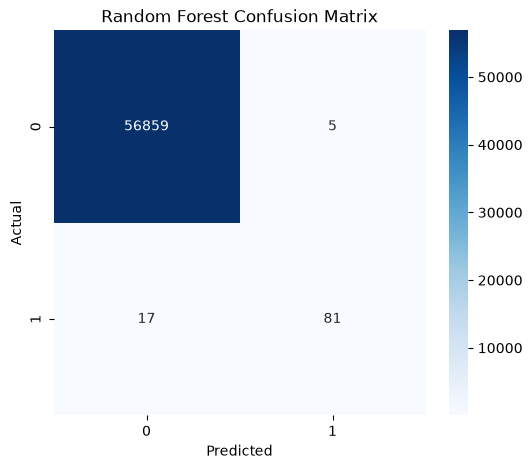

In [12]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

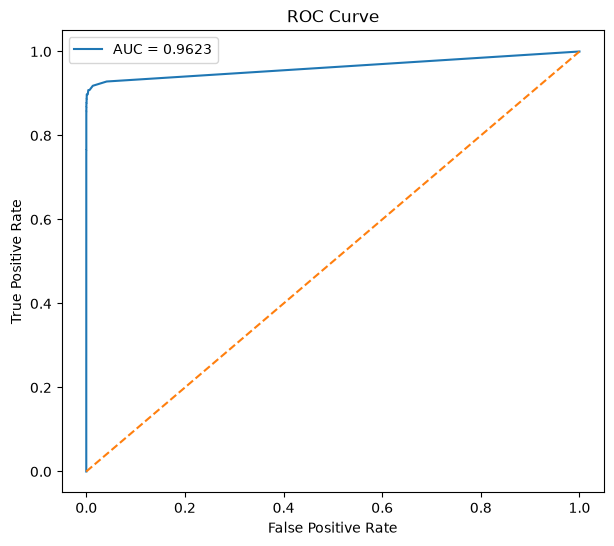

In [13]:
fpr,tpr,_ = roc_curve(y_test,y_prob)

roc_auc = roc_auc_score(y_test,y_prob)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {roc_auc:.4f}"
)

plt.plot(
    [0,1],
    [0,1],
    "--"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.show()

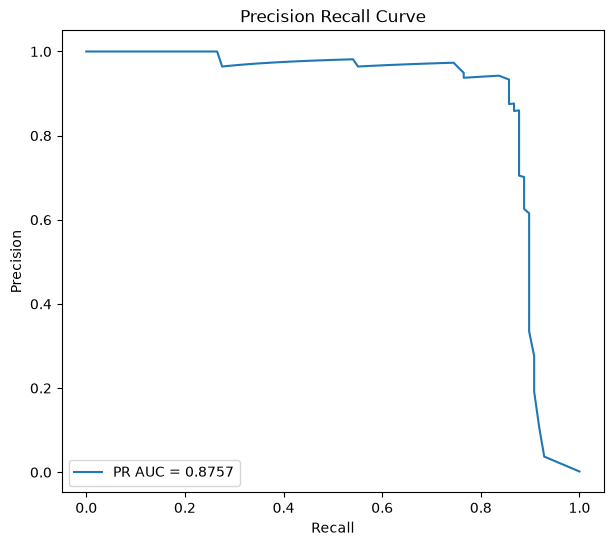

In [14]:
precision,recall,_ = precision_recall_curve(
    y_test,
    y_prob
)

pr_auc = auc(recall,precision)

plt.figure(figsize=(7,6))

plt.plot(
    recall,
    precision,
    label=f"PR AUC = {pr_auc:.4f}"
)

plt.xlabel("Recall")

plt.ylabel("Precision")

plt.title("Precision Recall Curve")

plt.legend()

plt.show()

In [15]:
importance = pd.DataFrame({

    "Feature":X_train.columns,

    "Importance":rf.feature_importances_

})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

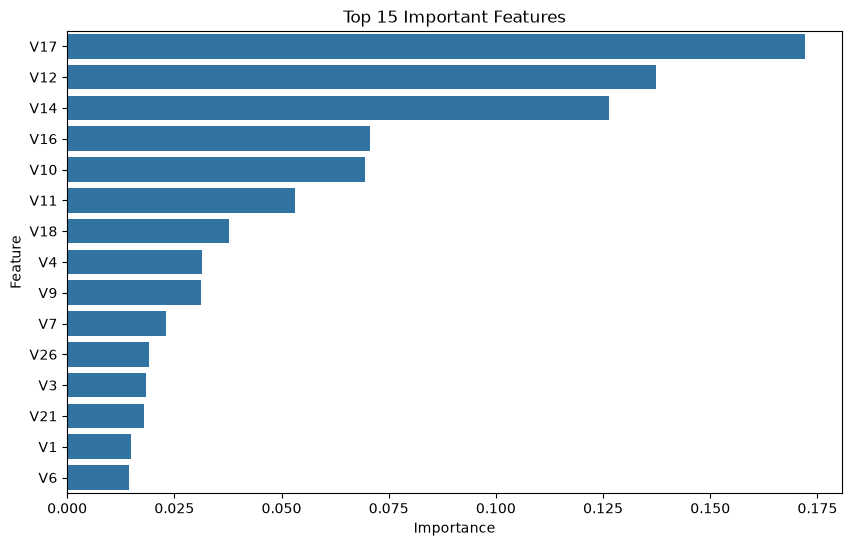

In [16]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features")

plt.show()

In [17]:
scores = cross_val_score(
    rf,
    X_train,
    y_train,
    cv=5,
    scoring="f1"
)

print(scores)

print("Average F1 :",scores.mean())

[0.80882353 0.8590604  0.84353741 0.85106383 0.84285714]
Average F1 : 0.8410684639413383


In [19]:
from scipy.stats import randint

param_grid = {

    "n_estimators":randint(100,400),

    "max_depth":randint(5,30),

    "min_samples_split":randint(2,10),

    "min_samples_leaf":randint(1,5)

}

In [20]:
search = RandomizedSearchCV(

    rf,

    param_distributions=param_grid,

    n_iter=10,

    cv=3,

    scoring="f1",

    verbose=2,

    random_state=42,

    n_jobs=-1

)

search.fit(X_train,y_train)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': <scipy.stats....0022049FE5310>, 'min_samples_leaf': <scipy.stats....0022049155E10>, 'min_samples_split': <scipy.stats....0022049FE4050>, 'n_estimators': <scipy.stats....00220494D3450>}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing

In [21]:
print(search.best_params_)

{'max_depth': 16, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 158}


In [22]:
best_rf = search.best_estimator_

In [23]:
joblib.dump(
    best_rf,
    "../models/best_random_forest.pkl"
)

['../models/best_random_forest.pkl']

In [ ]:
importance.to_csv(
    "../reports/feature_importance.csv",
    index=False
)